# E1 – Convergence with the number of clustered time steps

- **Goal:** Test how fast accuracy and runtime improve as clustered steps `K` increase toward the full year (`8,760` h).
- **Sweep:**
  - Target `K` ∈ `{24, 48, 96, 192, 384, 768, 1460, 2920}`.
  - Plots use *actual* clustered steps (targets are raised to `2 × max(series)` and extremes are added on top).
- **Test cases:**
  - **demo** (1 stage): `M1`, `M2` (`M1b` = `M1` for 1 stage), solved.
  - **ms3** (2 stages): `M1`, `M1b`, `M2`, solved.
  - **swissx** (4 stages): `M1`, `M1b`, `M2`, clustering quality only.
- *Method & metric definitions are in the **Appendix** of `E0_baseline.ipynb`.*

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print("Variants:", {k: v for k, v in rl.VARIANTS.items()})

Variants: {'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
K = [24, 48, 96, 192, 384, 768, 1460, 2920]
VARS = {"demo": ["M1", "M2"], "ms3": ["M1", "M1b", "M2"], "swissx": ["M1", "M1b", "M2"]}
COLORS = {"M1": "C0", "M1b": "C1", "M2": "C2"}
MODE = {"demo": "rom", "ms3": "rom", "swissx": "cluster"}
prof = {c: rl.run(c, "M0", "profiles") for c in VARS}
full = {c: rl.run(c, "M0", "full") for c in ("demo", "ms3")}
rows = []
for c, vs in VARS.items():
    for v in vs:
        for k in K:
            r = try_run(c, v, MODE[c], k)
            row = {"case": c, "variant": v, "target": k}
            if "error" in r:
                row["error"] = r["error"]; rows.append(row); continue
            row["num_ts"] = r["num_ts"]
            row["secs_cluster"] = r["secs_cluster"]
            st = rl.stage_summary(r, prof[c]["num_horizon_ts"])
            row["phantom"] = int(st.phantom.sum())
            if MODE[c] == "rom":
                row.update(rl.solution_compare(full[c], r))
            m = rl.series_metrics(prof[c], r)
            m = m[~m.constant]
            for col in ["wsum_err", "max_err", "min_err", "dc_nrmse", "chr_nrmse"]:
                row[col] = m[col].abs().mean()
            rows.append(row)
res = pd.DataFrame(rows)
print(f"Loaded {len(res)} runs ({int(res['num_ts'].isna().sum())} failed); full solve time [s]: " + str({c: round(full[c]["secs_solve"]) for c in full}))

Loaded 64 runs (0 failed); full solve time [s]: {'demo': 76, 'ms3': 144}


## 1. Model-level convergence (demo, ms3)

- **Metrics:** objective error (`obj_err`), relative capacity difference (`cap_abs_diff_rel`), and solve time (`secs_solve`).
- **Axes:** log scale for actual clustered steps; dashed/solid reference lines show `M0` full-year value (`0 %` error or full solve time).

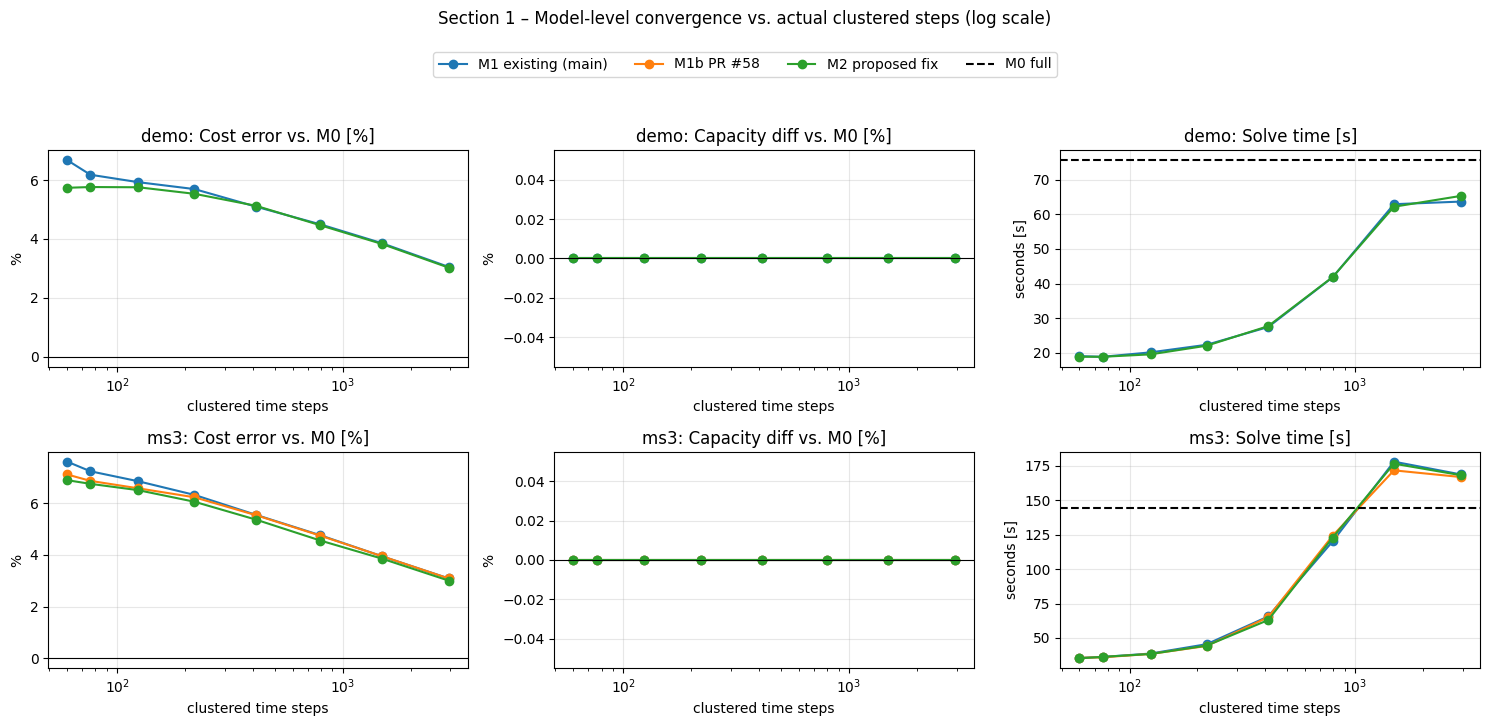

In [3]:
cols = [("obj_err", "Cost error vs. M0 [%]"), ("cap_abs_diff_rel", "Capacity diff vs. M0 [%]"), ("secs_solve", "Solve time [s]")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(["demo", "ms3"]):
    for j, (col, title) in enumerate(cols):
        ax = axes[i, j]
        for v in VARS[c]:
            d = res[(res.case == c) & (res.variant == v)].dropna(subset=["num_ts"])
            y = d[col] * (100 if col != "secs_solve" else 1)
            ax.plot(d.num_ts, y, marker="o", color=COLORS[v], label=rl.LABELS[v])
        if col == "secs_solve":
            ax.axhline(full[c]["secs_solve"], color="k", ls="--", label="M0 full")
        else:
            ax.axhline(0, color="k", lw=0.8)
        ax.set_xscale("log"); ax.set_xlabel("clustered time steps")
        ax.set_ylabel("%" if col != "secs_solve" else "seconds [s]")
        ax.set_title(f"{c}: {title}"); ax.grid(True, alpha=0.3)
handles, labels = axes[1, 2].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.98))
fig.suptitle("Section 1 – Model-level convergence vs. actual clustered steps (log scale)", y=1.03)
plt.tight_layout(rect=[0, 0, 1, 0.93])

**Summary (Section 1):**
- **Slow cost convergence:** `demo` `M2` drops only from `+5.7 %` (`60` steps) to `+3.0 %` (`2,948` steps, a third of the year); `ms3` goes `+6.9 %` → `+3.1 %`.
- **Method gap:** `M2` beats `M1` at small `K` (`5.7 %` vs. `6.7 %` on `demo`, `6.9 %` vs. `7.6 %` on `ms3`), then all three converge similarly.
- **Solve time:** ROM gives a modest `2–4×` speed-up (`19–65 s` vs. `76 s` on `demo`; `35–180 s` vs. `144 s` on `ms3`).

## 2. Input-level convergence (all cases)

- **Metrics:** mean absolute errors across non-constant series (`wsum_err`, `max_err`, `dc_nrmse`, `chr_nrmse`; `0` = exact match) plus clustering runtime (`secs_cluster`).
- **X-axis:** log scale for actual clustered time steps.

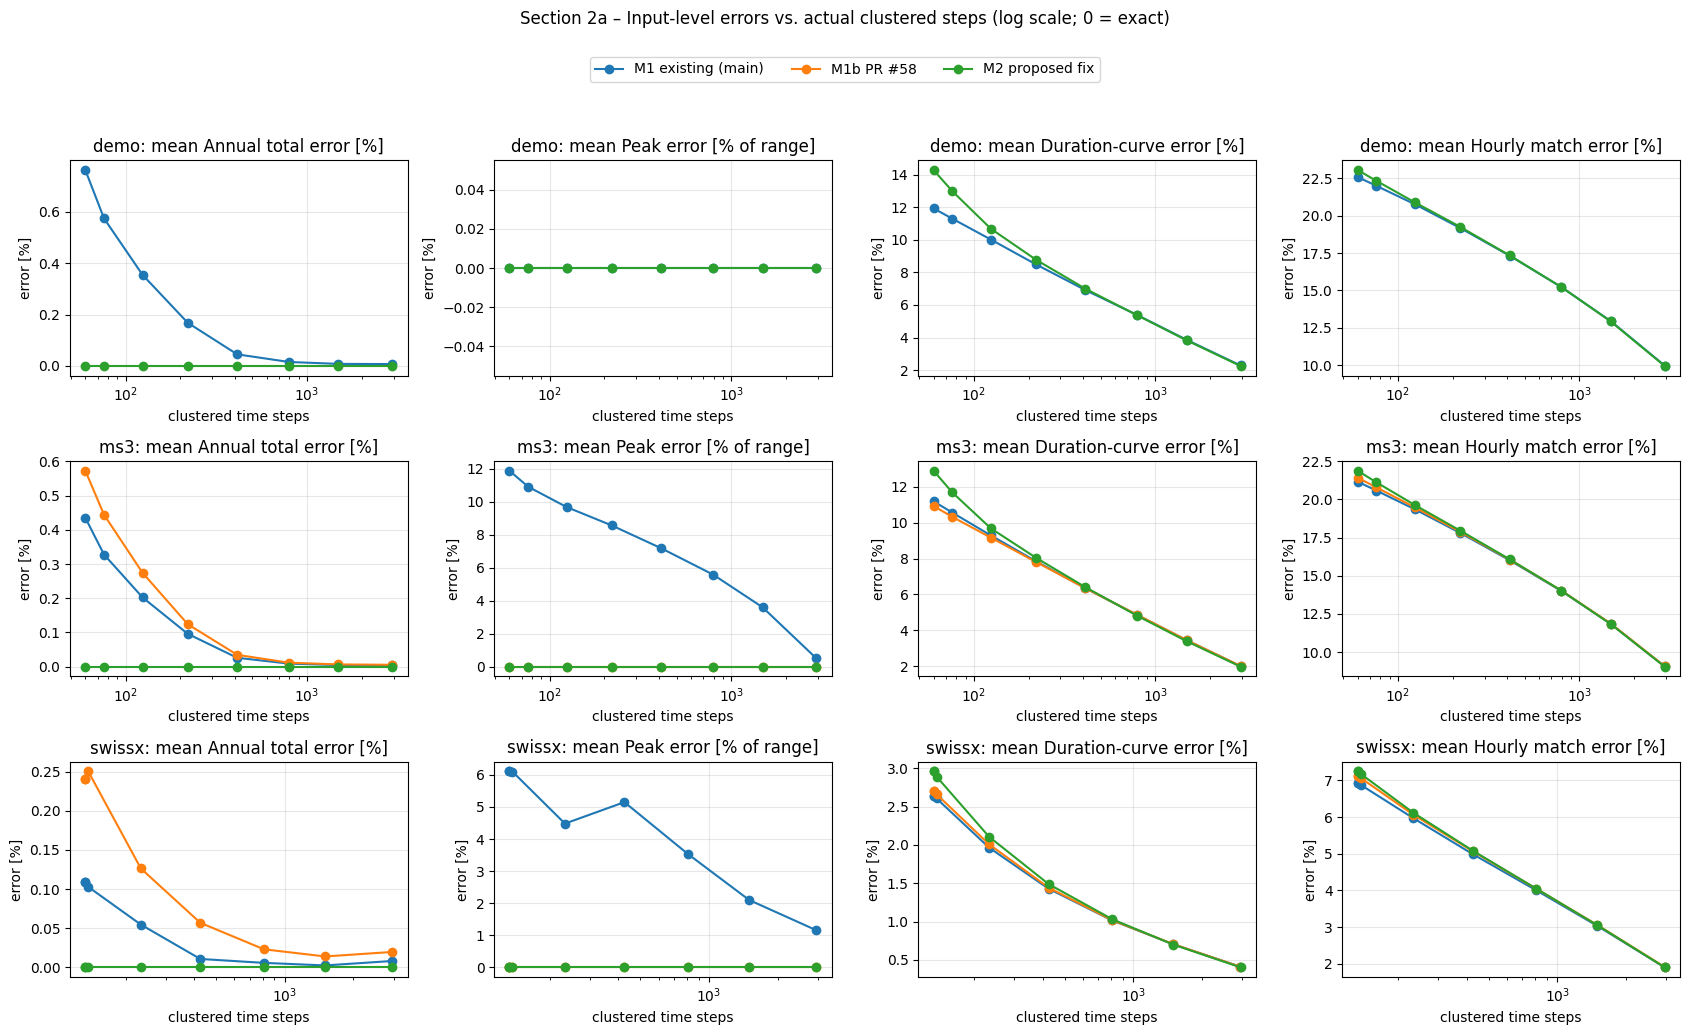

In [4]:
cols = [("wsum_err", "Annual total error [%]"), ("max_err", "Peak error [% of range]"),
        ("dc_nrmse", "Duration-curve error [%]"), ("chr_nrmse", "Hourly match error [%]")]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for i, c in enumerate(["demo", "ms3", "swissx"]):
    for j, (col, title) in enumerate(cols):
        ax = axes[i, j]
        for v in VARS[c]:
            d = res[(res.case == c) & (res.variant == v)].dropna(subset=["num_ts"])
            ax.plot(d.num_ts, d[col] * 100, marker="o", color=COLORS[v], label=rl.LABELS[v])
        ax.set_xscale("log"); ax.set_title(f"{c}: mean {title}")
        ax.set_xlabel("clustered time steps"); ax.set_ylabel("error [%]"); ax.grid(True, alpha=0.3)
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.99))
fig.suptitle("Section 2a – Input-level errors vs. actual clustered steps (log scale; 0 = exact)", y=1.03)
plt.tight_layout(rect=[0, 0, 1, 0.95])

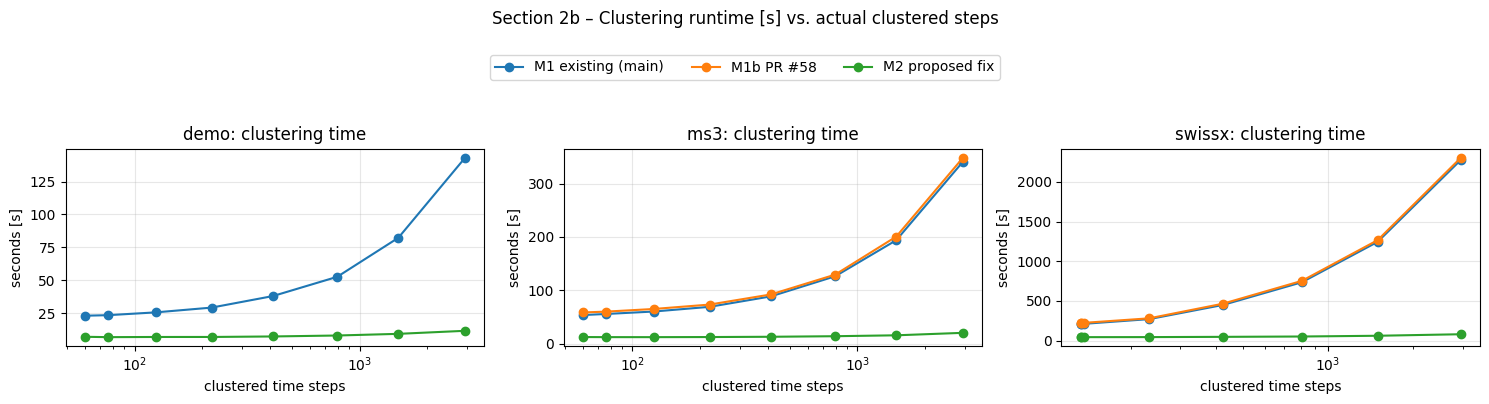

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, ["demo", "ms3", "swissx"]):
    for v in VARS[c]:
        d = res[(res.case == c) & (res.variant == v)].dropna(subset=["num_ts"])
        ax.plot(d.num_ts, d["secs_cluster"], marker="o", color=COLORS[v], label=rl.LABELS[v])
    ax.set_xscale("log"); ax.set_title(f"{c}: clustering time")
    ax.set_xlabel("clustered time steps"); ax.set_ylabel("seconds [s]"); ax.grid(True, alpha=0.3)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Section 2b – Clustering runtime [s] vs. actual clustered steps", y=1.05)
plt.tight_layout(rect=[0, 0, 1, 0.87])

**Summary (Section 2):**
- **Fast vs. slow input metrics:** `dc_nrmse` falls quickly (`0.14` → `0.02`), while `chr_nrmse` stays high (`0.23` → `0.10`), pointing to time/storage coupling as the main error source.
- **Method comparison:** `M2` keeps exact totals and peaks at all `K` and matches `M1` `dc_nrmse` from `~400` steps onward, while `M1` still loses up to `52 %` of peak range (`8 %` on `swissx` at `1,500` steps).
- **Clustering speed:** `M2` is much faster (`44–81 s` vs. `210–2,300 s` on `swissx`; `7–12 s` vs. `23–143 s` on `demo`).

## Findings (E1)

- **Key takeaway:**
  - Objective error converges slowly as `K` grows, even though input profile errors drop quickly.
  - The bottleneck is how typical-hour ROM couples time and storage, not profile accuracy.
- **Actual vs. target step count:**
  - Actual steps often exceed target `K` because of the `2 × max(series)` floor plus extreme steps:
    - `demo` / `ms3`: target `24` → `60` steps (`2 × 16` series + `28` extremes).
    - `swissx`: targets `24` and `48` both → `133` steps (`2 × 46` series + `41` extremes).
  - Below `~100` steps, the `2 × series` rule dominates.
- **Slow objective convergence:**
  - Cost error vs. full year (`M2`):
    - `demo`: `+5.7 %` (`60`) → `+5.5 %` (`220`) → `+4.5 %` (`796`) → `+3.8 %` (`1,488`) → **`+3.0 %`** (`2,948`, one-third of a year).
    - `ms3`: `+6.9 %` → `+3.1 %` over the same sweep.
  - Input errors drop much faster:
    - `M2` weighted totals: exact at every `K`.
    - Duration-curve error (`dc_nrmse`): `0.14` → `0.02`.
  - **Likely cause (time/storage coupling):**
    - All hours in a cluster share one set of operational dispatch variables.
    - In `stor_tech_model.py` (`_con_stor_tech_charging_dynamic`), storage energy level tracks all `8,760` horizon hours, while charging/discharging flows are indexed by clustered step.
    - Storage must therefore charge/discharge identically across hours scattered over the year, restricting operation and raising cost.
    - Slow decay of chronological error `chr_nrmse` (`0.23` → `0.10`) points the same way; share of error to be quantified in **E7**.
    - Chronology-preserving methods (**M3** typical days, **M4** downsampling) may behave very differently.
- **Methods compared (`M1`, `M1b`, `M2`):**
  - All three converge similarly overall, with `M2` consistently cleaner:
    - Lower small-`K` cost error: `5.7 %` vs. `6.7 %` (`demo` at `60` steps); `6.9 %` vs. `7.6 %` (`ms3`).
    - Exact annual totals and exact peaks/minima at every `K`.
    - Duration-curve error slightly higher at small `K`, equal from `~400` steps onward.
  - `M1` still loses up to `52 %` of peak range in multi-stage models (even `8 %` on `swissx` at `1,500` steps).
- **Runtime:**
  - **Clustering time (`M2` much faster):**
    - `swissx`: `44–81 s` (`M2`) vs. `210–2,300 s` (`M1`/`M1b`, due to `tsam` extreme handling and re-clustering).
    - `demo`: `7–12 s` (`M2`) vs. `23–143 s` (`M1`/`M1b`).
  - **Solve time (indicative, measured with 6 runs in parallel):**
    - Full horizon (`M0`): `76 s` (`demo`), `144 s` (`ms3`).
    - ROM: `19–65 s` (`demo`), `35–180 s` (`ms3`) — only `2–4×` speed-up on these small models.
- **Next steps:**
  - Prioritize **E7** (storage/time coupling) and **M3**/**M4** (chronology-preserving methods) over further tuning of typical-hour clustering (**E2**, **E3**).
  - Add a test model with **free capacities** to evaluate design differences.